In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
import pandas as pd
import numpy as np

DATA_DIR = "/kaggle/input/datasets/pravalika2303a51204/agricultural-pesticides"

for root, dirs, files in os.walk(DATA_DIR):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/datasets/pravalika2303a51204/agricultural-pesticides/pesticides.csv
/kaggle/input/datasets/pravalika2303a51204/agricultural-pesticides/rainfall.csv
/kaggle/input/datasets/pravalika2303a51204/agricultural-pesticides/temp.csv
/kaggle/input/datasets/pravalika2303a51204/agricultural-pesticides/yield.csv
/kaggle/input/datasets/pravalika2303a51204/agricultural-pesticides/yield_df.csv


In [5]:
# Replace this with the actual CSV path
FILE_PATH = "/kaggle/input/datasets/pravalika2303a51204/agricultural-pesticides/pesticides.csv"
df = pd.read_csv(FILE_PATH)

print("First 5 rows:")
display(df.head())

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

First 5 rows:


,Domain,Area,Element,Item,Year,Unit,Value
0,Pesticides Use,Albania,Use,Pesticides (total),1990,tonnes of active ingredients,121.0
1,Pesticides Use,Albania,Use,Pesticides (total),1991,tonnes of active ingredients,121.0
2,Pesticides Use,Albania,Use,Pesticides (total),1992,tonnes of active ingredients,121.0
3,Pesticides Use,Albania,Use,Pesticides (total),1993,tonnes of active ingredients,121.0
4,Pesticides Use,Albania,Use,Pesticides (total),1994,tonnes of active ingredients,201.0


Dataset shape: (4349, 7)

Column names:
['Domain', 'Area', 'Element', 'Item', 'Year', 'Unit', 'Value']


In [6]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4349 entries, 0 to 4348
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Domain   4349 non-null   object 
 1   Area     4349 non-null   object 
 2   Element  4349 non-null   object 
 3   Item     4349 non-null   object 
 4   Year     4349 non-null   int64  
 5   Unit     4349 non-null   object 
 6   Value    4349 non-null   float64
dtypes: float64(1), int64(1), object(5)
memory usage: 238.0+ KB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Domain,4349,1,Pesticides Use,4349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area,4349,168,Albania,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Element,4349,1,Use,4349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item,4349,1,Pesticides (total),4349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,4349.0,NaN,NaN,NaN,2003.138883,7.728044,1990.0,1996.0,2003.0,2010.0,2016.0
Unit,4349,1,tonnes of active ingredients,4349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Value,4349.0,NaN,NaN,NaN,20303.341465,117736.190448,0.0,93.0,1137.56,7869.0,1807000.0



Missing values:
Domain     0
Area       0
Element    0
Item       0
Year       0
Unit       0
Value      0
dtype: int64

Duplicate rows: 0


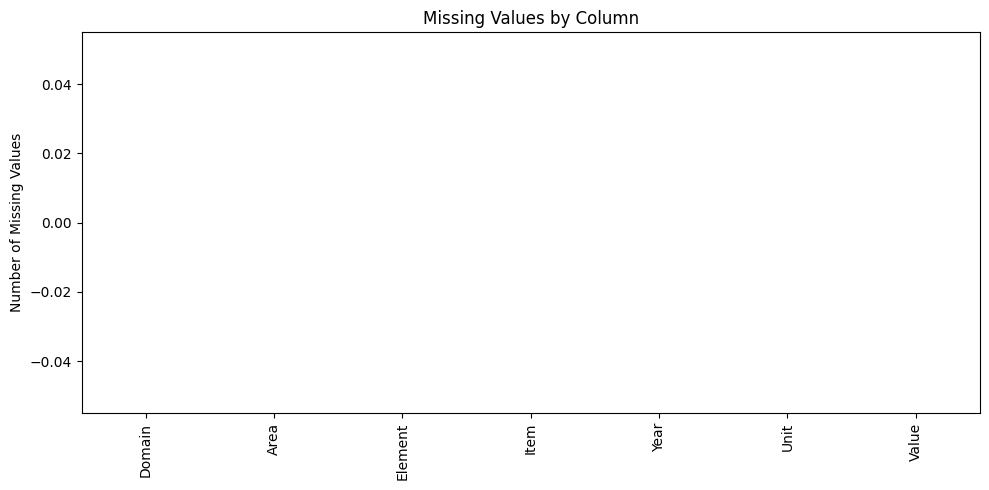

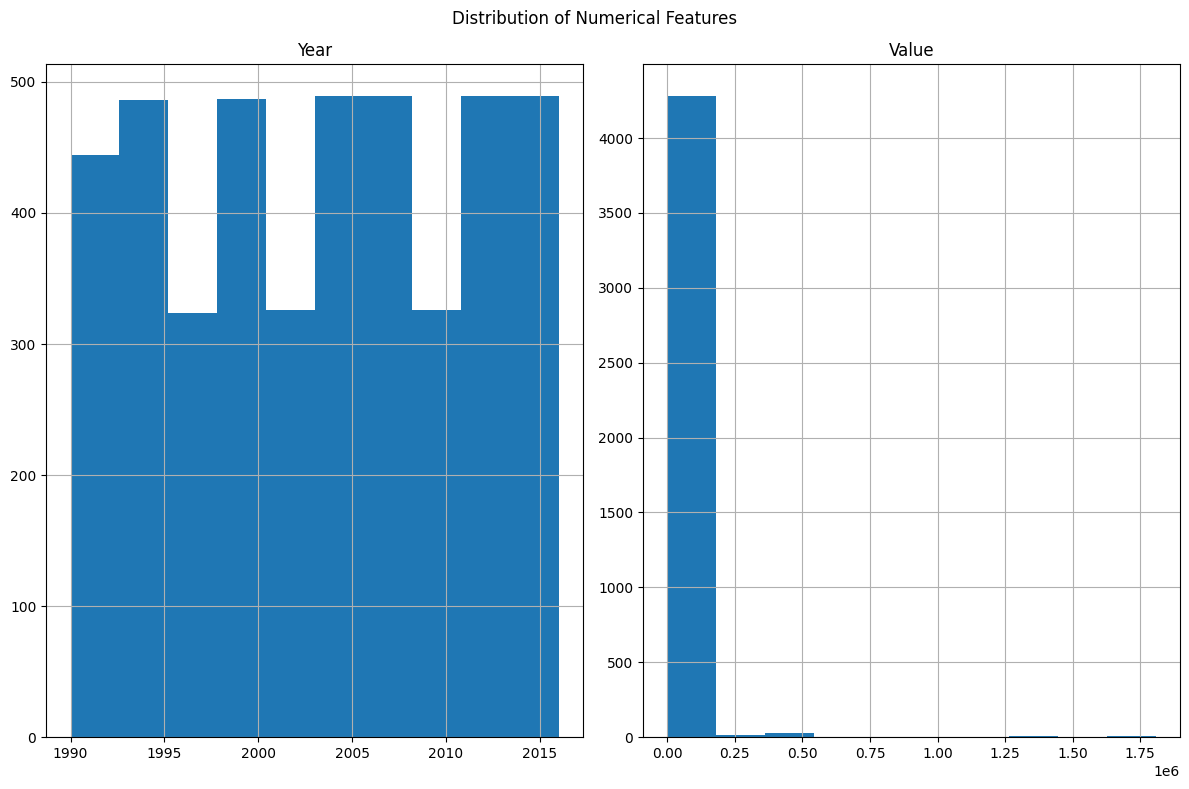

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Missing values chart
df.isnull().sum().sort_values(ascending=False).head(20).plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Missing Values by Column")
plt.ylabel("Number of Missing Values")
plt.tight_layout()
plt.show()

# Distribution of numerical columns
df.select_dtypes(include=np.number).hist(figsize=(12, 8))
plt.suptitle("Distribution of Numerical Features")
plt.tight_layout()
plt.show()

In [8]:
print("Available columns:")
for col in df.columns:
    print(col)

Available columns:
Domain
Area
Element
Item
Year
Unit
Value


In [10]:
import pandas as pd
import numpy as np

# Use the dataset you have already loaded
df.columns = df.columns.str.strip()

# Clean missing target values
df["Value"] = pd.to_numeric(df["Value"], errors="coerce")
df = df.dropna(subset=["Value"]).drop_duplicates()

# Select features and target
X = df.drop(columns=["Value"])
y = df["Value"]

print("Features:", X.columns.tolist())
print("Target: Value")
print("Dataset shape:", df.shape)

display(df.head())

Features: ['Domain', 'Area', 'Element', 'Item', 'Year', 'Unit']
Target: Value
Dataset shape: (4349, 7)


,Domain,Area,Element,Item,Year,Unit,Value
0,Pesticides Use,Albania,Use,Pesticides (total),1990,tonnes of active ingredients,121.0
1,Pesticides Use,Albania,Use,Pesticides (total),1991,tonnes of active ingredients,121.0
2,Pesticides Use,Albania,Use,Pesticides (total),1992,tonnes of active ingredients,121.0
3,Pesticides Use,Albania,Use,Pesticides (total),1993,tonnes of active ingredients,121.0
4,Pesticides Use,Albania,Use,Pesticides (total),1994,tonnes of active ingredients,201.0


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 3479
Testing samples: 870


In [12]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import time

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "SVR": SVR(),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    start = time.time()
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    elapsed = time.time() - start

    trained_models[name] = pipeline

    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Time (seconds)": round(elapsed, 2)
    })

results_df = pd.DataFrame(results).sort_values(
    "RMSE", ascending=True
)

display(results_df)

,Model,R2 Score,MAE,RMSE,Time (seconds)
6,Extra Trees,0.999493,817.426026,2987.974429,1.41
2,Random Forest,0.999162,1036.563365,3840.142168,1.56
3,KNN,0.997966,1428.618871,5981.985663,0.20
1,Decision Tree,0.997781,1363.458149,6248.677348,0.08
5,Gradient Boosting,0.993159,6411.933312,10971.674733,0.27
0,Linear Regression,0.934506,7492.415325,33948.791184,0.06
4,SVR,-0.026334,22447.136233,134389.957682,0.81


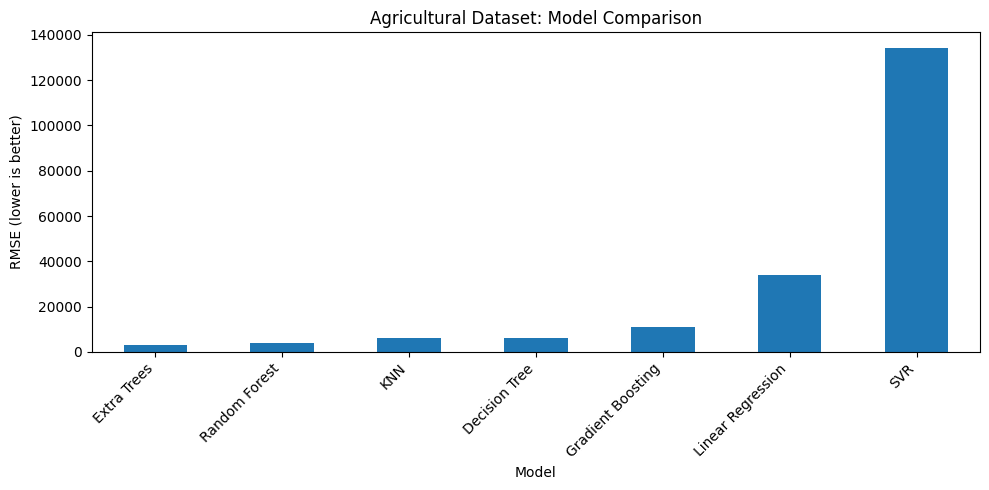

In [13]:
import matplotlib.pyplot as plt

results_df.sort_values("RMSE").plot(
    x="Model",
    y="RMSE",
    kind="bar",
    legend=False,
    figsize=(10, 5)
)

plt.title("Agricultural Dataset: Model Comparison")
plt.ylabel("RMSE (lower is better)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
import joblib

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Best model by RMSE:", best_name)
print(results_df.iloc[0])

joblib.dump(
    best_model,
    "/kaggle/working/best_agricultural_model.pkl"
)

Best model by RMSE: Extra Trees
Model             Extra Trees
R2 Score             0.999493
MAE                817.426026
RMSE              2987.974429
Time (seconds)           1.41
Name: 6, dtype: object


['/kaggle/working/best_agricultural_model.pkl']

In [16]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

predictions = best_model.predict(X_test)

print("Best Model:", best_name)
print("R2 Score:", r2_score(y_test, predictions))
print("MAE:", mean_absolute_error(y_test, predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))

Best Model: Extra Trees
R2 Score: 0.9994926488391611
MAE: 817.4260262068982
RMSE: 2987.9744292624887


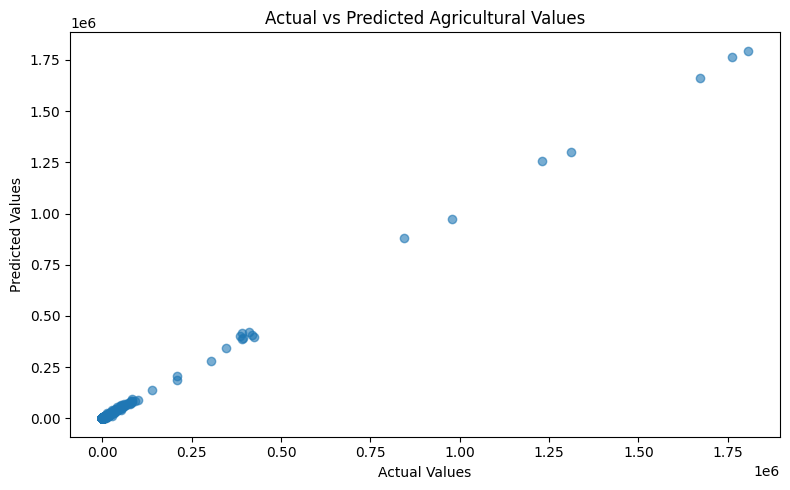

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(y_test, predictions, alpha=0.6)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Agricultural Values")

plt.tight_layout()
plt.show()

,Feature,Importance
37,"cat__Area_China, mainland",0.827131
161,cat__Area_United States of America,0.070286
0,num__Year,0.061251
23,cat__Area_Brazil,0.020957
57,cat__Area_France,0.002753
77,cat__Area_Italy,0.002672
6,cat__Area_Argentina,0.002365
79,cat__Area_Japan,0.002120
38,cat__Area_Colombia,0.001228
158,cat__Area_Ukraine,0.000960


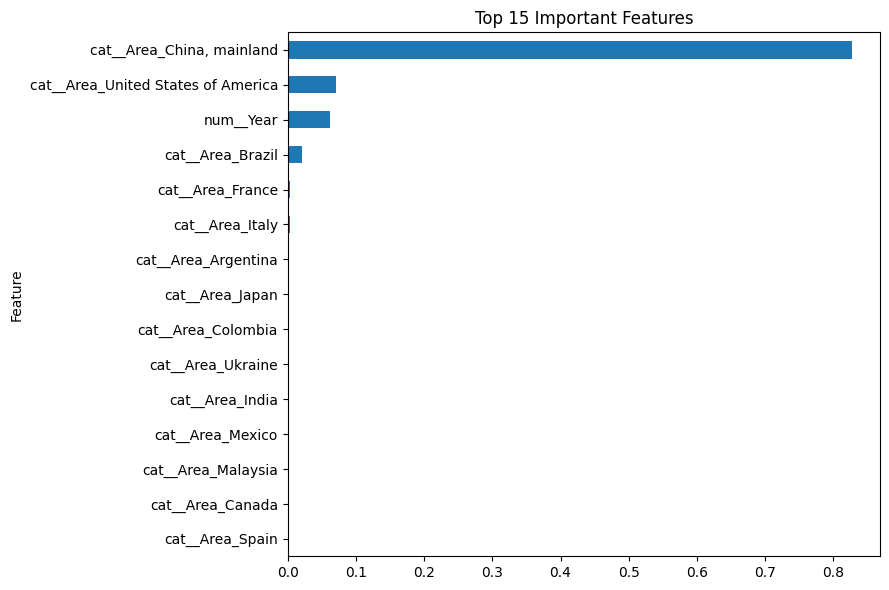

In [18]:
model = best_model.named_steps["model"]
preprocessor = best_model.named_steps["preprocessor"]

if hasattr(model, "feature_importances_"):
    names = preprocessor.get_feature_names_out()

    importance = pd.DataFrame({
        "Feature": names,
        "Importance": model.feature_importances_
    }).sort_values("Importance", ascending=False)

    display(importance.head(15))

    importance.head(15).sort_values("Importance").plot(
        x="Feature",
        y="Importance",
        kind="barh",
        figsize=(9, 6),
        legend=False
    )

    plt.title("Top 15 Important Features")
    plt.tight_layout()
    plt.show()
else:
    print("Feature importance is unavailable for this model.")

In [19]:
results_df.to_csv(
    "/kaggle/working/model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")



Model comparison saved successfully!


In [20]:
print("PROJECT: Agricultural Data Analysis")
print("------------------------------------")
print("Target column: Value")
print("Models trained:", len(trained_models))
print("Best model:", best_name)
print("Best model RMSE:", round(
    results_df.iloc[0]["RMSE"], 4
))
print("\nProject completed successfully!")

PROJECT: Agricultural Data Analysis
------------------------------------
Target column: Value
Models trained: 7
Best model: Extra Trees
Best model RMSE: 2987.9744

Project completed successfully!


In [21]:
print("Total models trained:", len(trained_models))

for name in trained_models:
    print(name)

Total models trained: 7
Linear Regression
Decision Tree
Random Forest
KNN
SVR
Gradient Boosting
Extra Trees


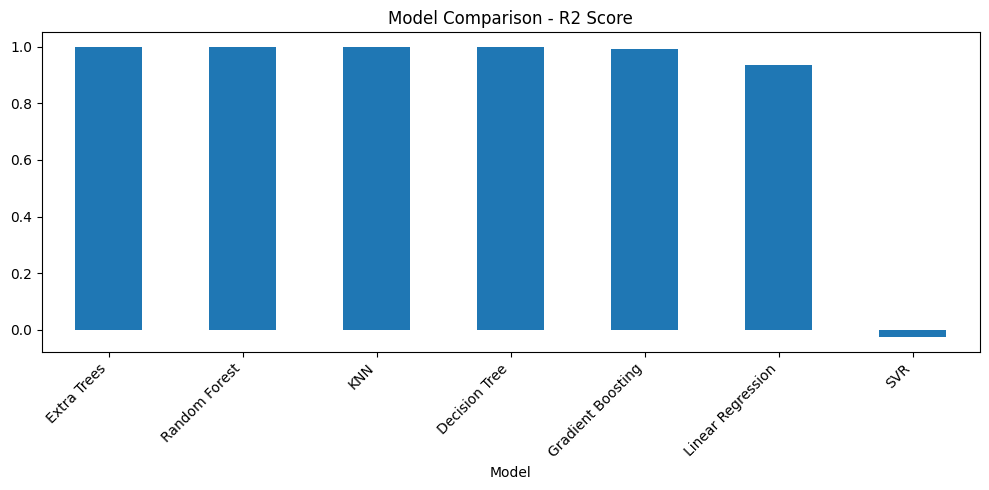

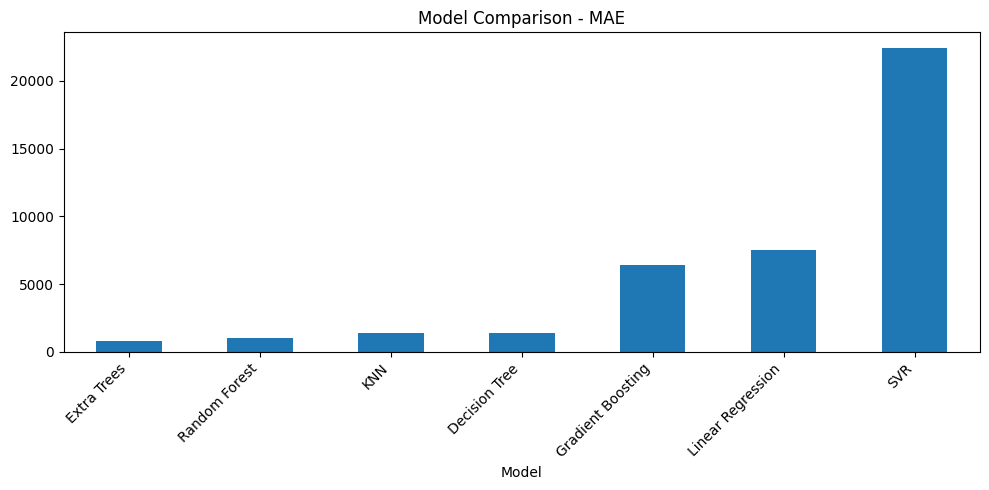

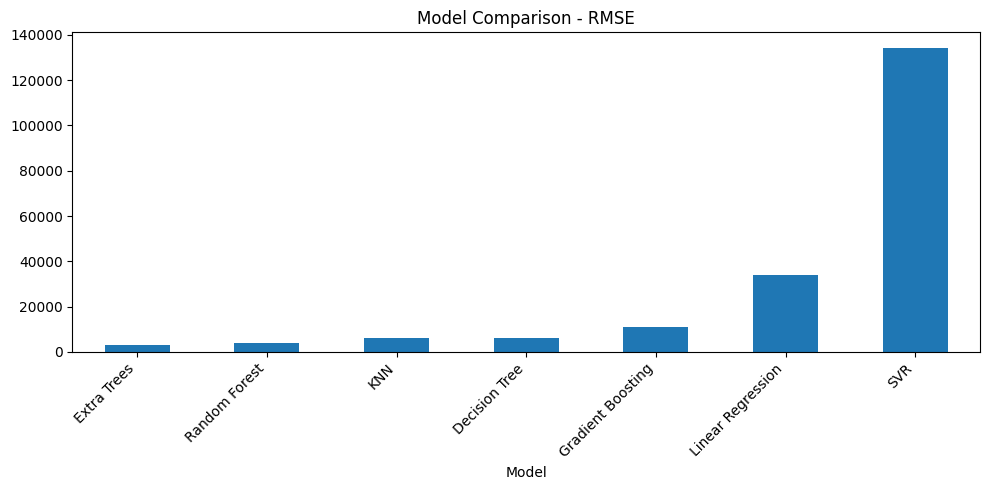

In [22]:
import matplotlib.pyplot as plt

metrics = ["R2 Score", "MAE", "RMSE"]

for metric in metrics:
    results_df.plot(
        x="Model", y=metric,
        kind="bar", figsize=(10, 5),
        legend=False
    )
    plt.title(f"Model Comparison - {metric}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

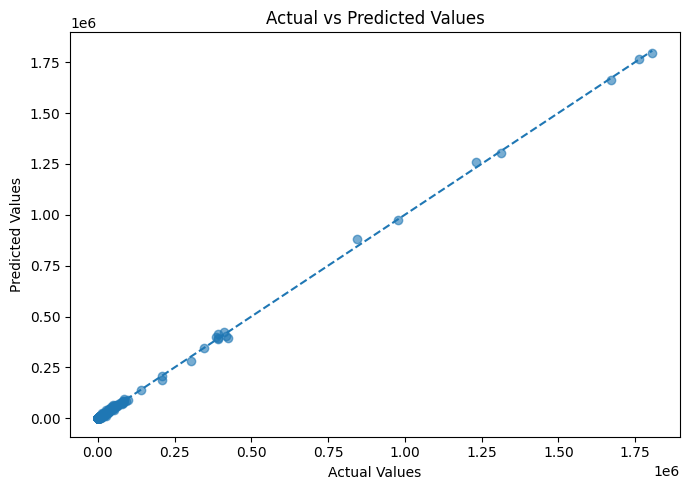

In [23]:
plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.6)

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], linestyle="--")

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Values")
plt.tight_layout()
plt.show()

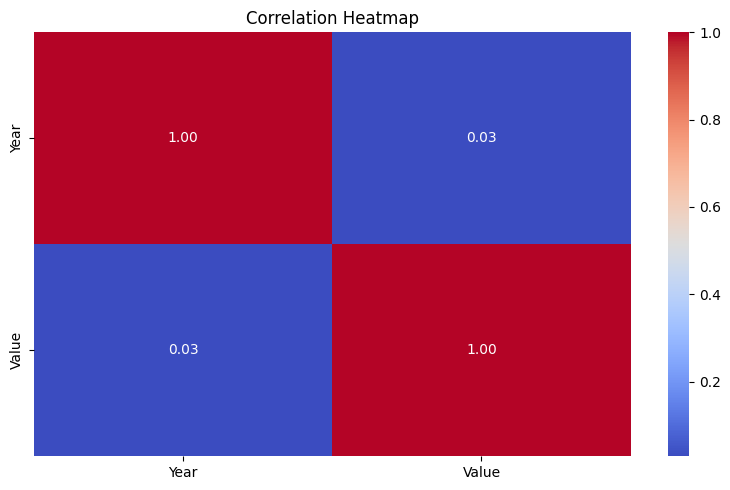

In [24]:
import seaborn as sns

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(8, 5))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

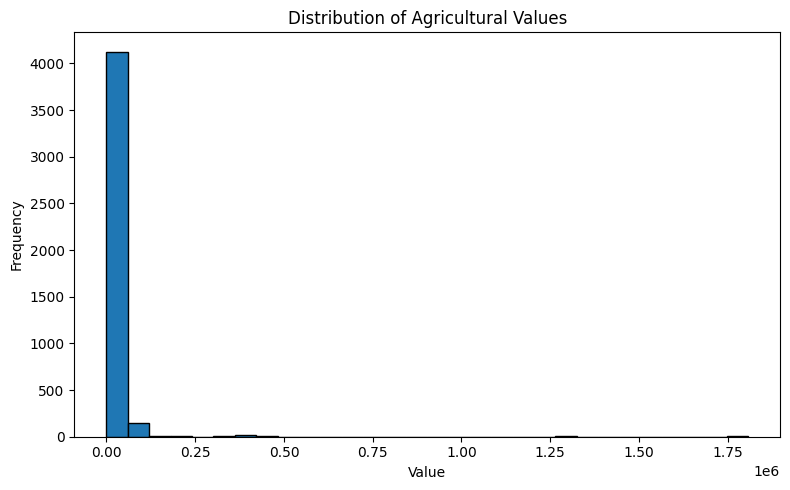

In [25]:
plt.figure(figsize=(8, 5))
plt.hist(df["Value"].dropna(), bins=30, edgecolor="black")

plt.xlabel("Value")
plt.ylabel("Frequency")
plt.title("Distribution of Agricultural Values")
plt.tight_layout()
plt.show()